# Suicídio e a alta do jogo patológico

O atendimento por jogo patológico (F63.0) nos CAPS cresceu ~7× de 2022 para 2025, com o maior crescimento entre
**mulheres de 18 a 44 anos**. Se isso reflete sofrimento grave, um lugar para procurar é o **suicídio**.

**Cuidado de interpretação.** Suicídio tem muitas causas, e a taxa brasileira já vinha subindo havia anos, sobretudo
entre jovens. O jogo patológico atinge alguns milhares de pessoas atendidas; o suicídio, ~16 mil mortes por ano. Uma
relação causal não aparece numa série nacional. Aqui a pergunta é mais modesta: **a tendência mudou depois de 2022 nos
grupos em que o jogo patológico mais cresceu?**

**Dados:** SIM (declarações de óbito), via `uv run python -m src.saude_mental.graves_f63 --so-sim`, agregado por mês, UF,
sexo e faixa etária. População: projeção do IBGE por sexo e idade (SIDRA 7358).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import datetime as dt
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from src.config import CHOQUES, PANDEMIA, pasta

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.2f}".format)
MIN_CELULA = 5


def marcar(ax):
    ini, fim = pl.Series(PANDEMIA).str.to_date()
    ax.axvspan(ini, fim, color="gray", alpha=0.15, lw=0)
    for i, (d, rot) in enumerate(CHOQUES.items(), 1):
        x = pl.Series([d]).str.to_date()[0]
        ax.axvline(x, color="crimson", ls="--", lw=0.8, alpha=0.7)
        ax.text(x, 1.0, f" {i}", va="top", fontsize=8, color="crimson", transform=ax.get_xaxis_transform())

## Decisões

**Suicídio:** causa básica X60–X84 (lesões autoprovocadas intencionalmente), a definição usual do Ministério da Saúde.

**Anos.** O SIM definitivo vai até **2024**. **2025 e 2026 são preliminares** (pasta `PRELIM` do DATASUS): ainda faltam
declarações e causas a investigar, e os números costumam subir na versão final. 2026 vai até agosto. A comparação
principal usa **2022 → 2024** (definitivos). 2025 aparece como indicação.

**Taxa por 100 mil.** Usamos a projeção de população do IBGE por sexo e idade (edição 2018, a última com idade simples
por ano). Ela é anterior ao Censo 2022 e superestima um pouco a população, mas serve para comparar a **evolução** das
taxas. É importante aqui porque a faixa de 35–44 anos está crescendo (as gerações grandes dos anos 1980 chegaram nela),
o que aumenta as mortes nessa faixa mesmo sem aumento de risco.

**Pré e pós.** Comparamos a variação **antes** do boom de tratamento (2018 → 2022, que inclui a pandemia) com a variação
**depois** (2022 → 2024), grupo a grupo. A pergunta é se a aceleração (ou falta de desaceleração) se concentra nos grupos
com mais F63.0.

In [2]:
sim = (pl.read_parquet(pasta("internacoes_obitos") / "sim_graves.parquet")
       .with_columns(pl.col("cmp").str.slice(0, 4).cast(pl.Int32, strict=False).alias("ano"),
                     pl.col("cmp").str.to_date("%Y%m", strict=False).alias("data"))
       .filter(pl.col("ano").is_between(2018, 2026)))

proj = json.loads((pasta("ibge", "raw") / "projecao_sexo_idade.json").read_text())[1:]
linhas = []
for r in proj:
    m = re.fullmatch(r"(\d+) anos?( ou mais)?", r["D5N"])
    if m and r["V"].isdigit():
        linhas.append({"ano": int(r["D6N"]), "sexo": "M" if r["D4N"] == "Homens" else "F", "idade": int(m.group(1)), "pop": int(r["V"])})
pop = pl.DataFrame(linhas)
faixa = (pl.when(pl.col("idade") <= 17).then(pl.lit("0-17")).when(pl.col("idade") <= 24).then(pl.lit("18-24"))
         .when(pl.col("idade") <= 34).then(pl.lit("25-34")).when(pl.col("idade") <= 44).then(pl.lit("35-44"))
         .when(pl.col("idade") <= 59).then(pl.lit("45-59")).otherwise(pl.lit("60+")))
pop = pop.with_columns(faixa.alias("faixa")).group_by("ano", "sexo", "faixa").agg(pl.col("pop").sum())
print("população projetada 2024 (milhões):", round(pop.filter(pl.col("ano") == 2024)["pop"].sum() / 1e6, 1))

população projetada 2024 (milhões): 222.9


## 1. Série nacional

Text(0.5, 1.0, 'Óbitos por suicídio por mês, Brasil')

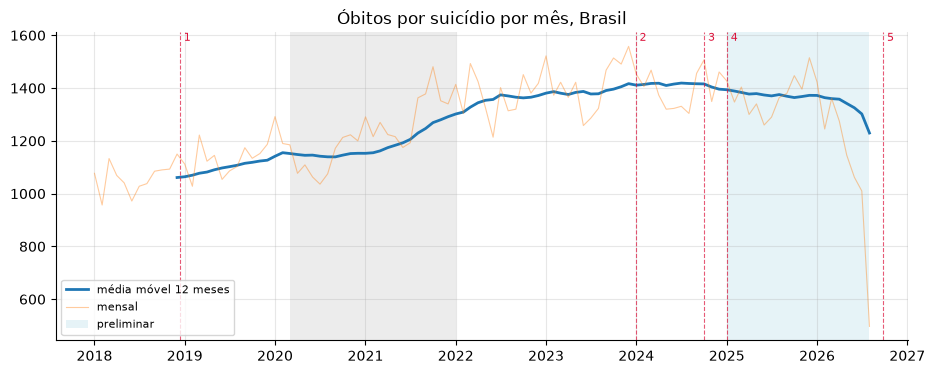

In [3]:
mens = sim.group_by("data").agg(pl.col("obitos_suicidio").sum()).sort("data")
fig, ax = plt.subplots()
ax.plot(mens["data"], mens["obitos_suicidio"].rolling_mean(12), lw=2, label="média móvel 12 meses")
ax.plot(mens["data"], mens["obitos_suicidio"], lw=0.8, alpha=0.4, label="mensal")
ax.axvspan(dt.date(2025, 1, 1), mens["data"].max(), color="lightblue", alpha=0.3, lw=0, label="preliminar")
marcar(ax); ax.legend(fontsize=8); ax.set_title("Óbitos por suicídio por mês, Brasil")

In [4]:
anual = (sim.group_by("ano").agg(pl.col("obitos_suicidio", "obitos_total").sum(), pl.col("data").dt.month().max().alias("meses")).sort("ano")
         .join(pop.group_by("ano").agg(pl.col("pop").sum()), on="ano", how="left")
         .with_columns((pl.col("obitos_suicidio") / pl.col("pop") * 1e5).alias("taxa por 100 mil"),
                       pl.when(pl.col("ano") >= 2025).then(pl.lit("preliminar")).otherwise(pl.lit("definitivo")).alias("status")))
anual.drop("pop").to_pandas().set_index("ano")

,obitos_suicidio,obitos_total,meses,taxa por 100 mil,status
ano,,,,,
2018,12733,1316719,12,5.99,definitivo
2019,13520,1349801,12,6.31,definitivo
2020,13835,1556824,12,6.40,definitivo
2021,15499,1832649,12,7.11,definitivo
2022,16462,1544266,12,7.50,definitivo
2023,17002,1465610,12,7.68,definitivo
2024,16751,1532015,12,7.52,definitivo
2025,16470,1534588,12,7.34,preliminar
2026,9019,912010,8,3.99,preliminar


A taxa de 2026 não é anual (só até agosto e preliminar) e não deve ser comparada.

## 2. Por sexo e idade: antes e depois de 2022

In [5]:
grp = (sim.drop_nulls(["sexo", "faixa"]).group_by("ano", "sexo", "faixa").agg(pl.col("obitos_suicidio").sum())
       .join(pop, on=["ano", "sexo", "faixa"], how="left").with_columns((pl.col("obitos_suicidio") / pl.col("pop") * 1e5).alias("taxa")))
tx = grp.pivot(on="ano", index=["sexo", "faixa"], values="taxa").sort("sexo", "faixa")
tab = tx.select("sexo", "faixa", *[pl.col(str(a)).alias(f"taxa {a}") for a in (2018, 2022, 2024, 2025)],
                (pl.col("2022") / pl.col("2018")).alias("variação 2018→2022"),
                (pl.col("2024") / pl.col("2022")).alias("variação 2022→2024"),
                (pl.col("2025") / pl.col("2022")).alias("variação 2022→2025 (prelim.)"))
tab.to_pandas().set_index(["sexo", "faixa"])

taxa 2018  taxa 2022  taxa 2024  taxa 2025  variação 2018→2022  \
sexo faixa                                                                   
F    0-17        0.95       1.20       0.89       1.15                1.26   
     18-24       2.97       4.03       4.28       4.11                1.36   
     25-34       2.68       4.17       4.52       4.28                1.56   
     35-44       3.05       3.97       4.54       4.63                1.30   
     45-59       3.65       4.19       4.33       4.06                1.15   
     60+         2.61       2.59       2.40       2.27                0.99   
M    0-17        1.43       1.51       1.31       1.47                1.06   
     18-24      11.26      15.30      14.53      13.61                1.36   
     25-34      12.27      15.89      16.74      17.43                1.29   
     35-44      13.07      16.91      16.63      16.24                1.29   
     45-59      13.41      15.91      15.98      15.07                1.19   
     60+        12.96      14.24      13.73      12.76                1.10   

            variação 2022→2024  variação 2022→2025 (prelim.)  
sexo faixa                                                    
F    0-17                 0.75                          0.96  
     18-24                1.06                          1.02  
     25-34                1.08                          1.03  
     35-44                1.14                          1.17  
     45-59                1.03                          0.97  
     60+                  0.93                          0.88  
M    0-17                 0.87                          0.98  
     18-24                0.95                          0.89  
     25-34                1.05                          1.10  
     35-44                0.98                          0.96  
     45-59                1.00                          0.95  
     60+                  0.96                          0.90

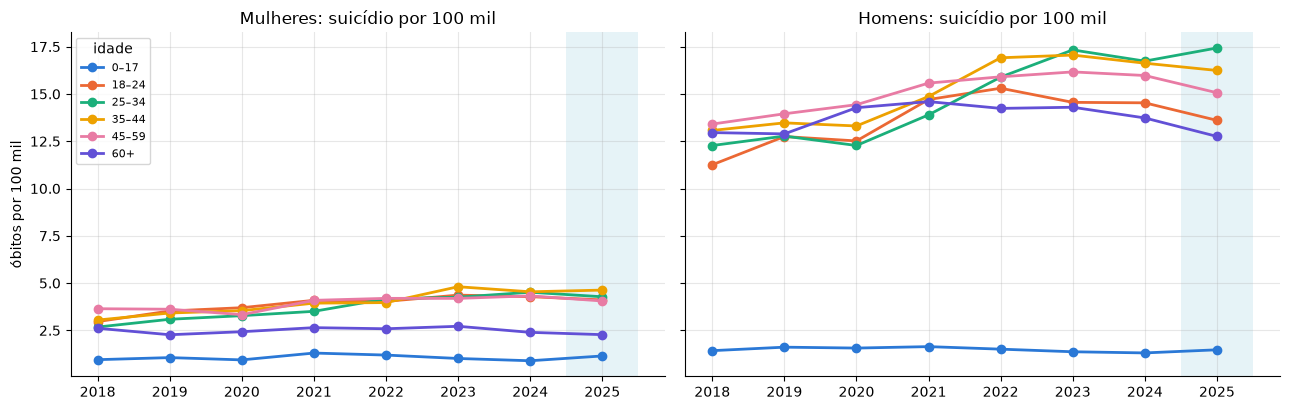

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
cores = {"0-17": "#2a78d6", "18-24": "#eb6834", "25-34": "#1baf7a", "35-44": "#eda100", "45-59": "#e87ba4", "60+": "#6250d6"}
for ax, sx, nome in [(axes[0], "F", "Mulheres"), (axes[1], "M", "Homens")]:
    for fx, cor in cores.items():
        d = grp.filter((pl.col("sexo") == sx) & (pl.col("faixa") == fx) & (pl.col("ano") <= 2025)).sort("ano")
        ax.plot(d["ano"], d["taxa"], marker="o", lw=2, color=cor, label=fx.replace("-", "–"))
    ax.axvspan(2024.5, 2025.5, color="lightblue", alpha=0.3, lw=0)
    ax.set_title(f"{nome}: suicídio por 100 mil"); ax.set_xticks(range(2018, 2026))
axes[0].legend(fontsize=8, title="idade"); axes[0].set_ylabel("óbitos por 100 mil")
plt.tight_layout()

**Decisão — ritmo anual.** As janelas têm tamanhos diferentes (4 anos antes, 2 depois), então as variações totais não
se comparam diretamente. A tabela abaixo converte cada uma em **variação média por ano** (taxa composta).

In [7]:
ritmo = tx.select("sexo", "faixa",
                  (((pl.col("2022") / pl.col("2018")) ** (1 / 4) - 1) * 100).alias("%/ano 2018→2022"),
                  (((pl.col("2024") / pl.col("2022")) ** (1 / 2) - 1) * 100).alias("%/ano 2022→2024"))
ritmo = ritmo.with_columns((pl.col("%/ano 2022→2024") - pl.col("%/ano 2018→2022")).alias("mudança de ritmo (p.p.)"))
ritmo.sort("mudança de ritmo (p.p.)", descending=True).to_pandas().set_index(["sexo", "faixa"])

%/ano 2018→2022  %/ano 2022→2024  mudança de ritmo (p.p.)
sexo faixa                                                           
F    35-44             6.84             6.94                     0.10
     45-59             3.57             1.56                    -2.01
     60+              -0.25            -3.74                    -3.49
M    25-34             6.67             2.63                    -4.04
     45-59             4.37             0.22                    -4.15
     60+               2.38            -1.79                    -4.17
F    18-24             7.99             3.03                    -4.96
M    35-44             6.66            -0.85                    -7.51
F    25-34            11.70             4.11                    -7.60
M    0-17              1.36            -6.84                    -8.20
     18-24             7.98            -2.55                   -10.53
F    0-17              5.86           -13.48                   -19.34

## 3. Jogo patológico mencionado na declaração de óbito

Procuramos F63 em qualquer linha da declaração (causa básica ou condições contribuintes). O jogo quase nunca é anotado:
o número é tão pequeno que fica suprimido (menos de 5) em quase todos os anos.

In [8]:
men = sim.group_by("ano").agg(pl.col("obitos_f63_mencionado", "obitos_f630_mencionado").sum()).sort("ano")
men.with_columns([pl.when(pl.col(c) < MIN_CELULA).then(None).otherwise(pl.col(c)).alias(c) for c in ["obitos_f63_mencionado", "obitos_f630_mencionado"]]).to_pandas().set_index("ano")

,obitos_f63_mencionado,obitos_f630_mencionado
ano,,
2018,NaN,NaN
2019,6.00,NaN
2020,5.00,NaN
2021,5.00,NaN
2022,NaN,NaN
2023,NaN,NaN
2024,5.00,NaN
2025,NaN,NaN
2026,9.00,5.00


## Leitura

**1. A taxa de suicídio subiu até 2023 e depois estabilizou, justamente quando o jogo patológico disparou.** De 6,0 por
100 mil (2018) para 7,5 (2022) e 7,7 (2023); depois 7,5 em 2024 e 7,3 em 2025 (preliminar). A grande alta veio antes do
boom de tratamento e atravessou a pandemia. No agregado nacional, **não há sinal** de que a alta do F63.0 a partir de 2024
tenha sido acompanhada de mais suicídios.

**2. Quase todos os grupos desaceleraram depois de 2022, com uma exceção: mulheres de 35 a 44 anos.** Na comparação pelo
ritmo anual, a taxa das mulheres de 35–44 anos continuou subindo ~7% ao ano (3,97 → 4,54 por 100 mil de 2022 a 2024;
4,63 em 2025, preliminar), enquanto as de 25–34 anos passaram de ~12% para ~4% ao ano, e os homens jovens pararam de subir
ou caíram. É o mesmo grupo em que o F63.0 cresceu ~20× de 2022 para 2025.

**Isso não mostra que o jogo causa esses suicídios.** São ~100 mortes a mais por ano (677 em 2022, 782 em 2024) num grupo de ~17 milhões
de mulheres, e no máximo algumas centenas de mulheres dessa idade estão em tratamento por jogo nos CAPS. A coincidência pode ter outras causas
(endividamento, violência doméstica, saúde mental pós-pandemia) que também afetam esse grupo. O que dá para dizer é que
o grupo em que o jogo patológico mais cresce é também o único em que o suicídio não desacelerou. Vale acompanhar
quando o SIM de 2025 for fechado.

**3. O jogo quase nunca é anotado na declaração de óbito.** F63 aparece em no máximo 5 a 9 declarações por ano, a
maioria suprimida (menos de 5). Mesmo quando há relação, a declaração não registra. Uma ligação individual exigiria
cruzar as bases (o CAPS com o SIM), o que não é possível com dados públicos.

**Limites:** população da projeção IBGE 2018, anterior ao Censo 2022; 2025–2026 preliminares; taxa nacional, sem separar
UF. Não usamos internações por autolesão (SIH) porque o download foi interrompido antes de terminar.